# 02 - Rating Distributions, Cross-Position Scale and Ceilings

Three questions about what the rating looks like, answered from the model's own outputs (no external reference exists,
so true agreement against a second rater stays out of scope):

- **A. Output distribution.** What does the distribution look like against minutes, against the match supremacy scalar, by
  career, and for goalkeepers?
- **B. Cross-position scale.** Is a rating equally reachable from an equally elite (relative to peers) performance in every
  position, and where does any gap come from?
- **C. Ceilings.** How much of the top of the scale is reachable, and by what?

A single-position rating is `clip(base_rating + bonus - supremacy_deduction, 0, 10)` with `base_rating = sigmoid(dot)`, so every
term is in rating points and Part B attributes cross-position gaps directly (`workshop/lib/decompose.py`, reconciled against the
service for every performance by a test).

Position groups use the first listed position; groups with too few rows for a comparison are left out and said so.

In [1]:
from pathlib import Path
import json
import sys
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.stats as stats
import seaborn as sns

project_root = Path("..").resolve().parent
if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

from workshop.lib import crossval, datasets, decompose, fit, gate, inference, rating, refit, sweep, variants
from workshop.lib.report import ci, header, say

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

In [2]:
info = header()

**Validated config: `005d563f`** | run 2026-10-25

- Config fitted on: arsenal_2 1-38, ipswich_3 1-22, valencia_cf_1 1-157
- Data analysed (matches per career): arsenal_2 (38), ipswich_3 (22), valencia_cf_1 (157)

In [3]:
RANDOM_SEED = 42
N_BOOTSTRAP_RESAMPLES = 5000
N_PERCENTILE_BINS = 10
MIN_BIN_ROWS = 10
MIN_SAMPLES_PER_BIN = 15
MIN_GROUP_ROWS = 30
MIN_TOP_ROWS = 10
REFERENCE_POSITION = "CM"
SCALE_GAP_BANDS = {"comparable": (0.0, 0.3), "mild_divergence": (0.3, 0.6), "substantial_divergence": (0.6, 10.0)}


def classify_scale_gap(gap: float) -> str:
    return next((k for k, (lo, hi) in SCALE_GAP_BANDS.items() if lo <= abs(gap) < hi), "substantial_divergence")


POSITION_GROUP_MAP = {
    "ST": "ST", "CF": "ST", "LW": "Winger", "RW": "Winger", "LM": "WM", "RM": "WM",
    "CAM": "CAM", "CM": "CM", "CDM": "CDM", "CB": "CB", "LB": "Fullback", "RB": "Fullback",
}
GROUP_ORDER = ["ST", "Winger", "WM", "CAM", "CM", "CDM", "CB", "Fullback"]
KEYS = ["career", "match_id", "player_id"]

## Data

In [4]:
rated = rating.rated_performances("pool")
rated = rated[rated["rating"].notna()].copy()
gk = rated[rated["performance_type"] == "GK"].copy()
perf = rated[rated["performance_type"] == "Outfield"].copy()
perf["group"] = perf["primary_position"].map(POSITION_GROUP_MAP)

dec = decompose.decompose_outfield("pool")
dec["group"] = dec["position"].map(POSITION_GROUP_MAP)
dec["event_bonus"] = dec["goal_bonus"] + dec["assist_bonus"]
dec["pre_supremacy"] = dec["base_rating"] + dec["bonus"]
dec["non_scoring_dot"] = dec["dot"] - dec["scoring_dot"]
dec["match_key"] = dec["career"] + ":" + dec["match_id"].astype(str)
context = datasets.matches("pool")[["career", "match_id", "team_xg", "opp_xg"]]
dec = dec.merge(context, on=["career", "match_id"], how="left", validate="m:1")
dec["xg_diff"] = dec["team_xg"] - dec["opp_xg"]

counts = pd.DataFrame({
    "rated outfield": perf.groupby("career").size(),
    "single-position": dec.groupby("career").size(),
    "goalkeeper": gk.groupby("career").size(),
})
counts["multi-position"] = counts["rated outfield"] - counts["single-position"]
display(counts)

group_counts = dec.pivot_table(index="group", columns="career", values="rating", aggfunc="count", fill_value=0)
group_counts["total"] = group_counts.sum(axis=1)
group_counts = group_counts.reindex([g for g in GROUP_ORDER if g in group_counts.index])
display(group_counts)
usable = group_counts.index[group_counts["total"] >= MIN_GROUP_ROWS].tolist()
dec_g = dec[dec["group"].isin(usable)].copy()
left_out = [g for g in group_counts.index if g not in usable]
say(f"Groups compared: **{', '.join(usable)}**" + (f"; left out for too few rows: {', '.join(left_out)}." if left_out else "."))

,rated outfield,single-position,goalkeeper,multi-position
career,,,,
arsenal_2,532,511,38,21
ipswich_3,291,280,22,11
valencia_cf_1,2219,2141,157,78


career,arsenal_2,ipswich_3,valencia_cf_1,total
group,,,,
ST,59,26,237,322
Winger,93,3,450,546
WM,11,58,0,69
CAM,0,27,2,29
CM,103,4,429,536
CDM,53,56,199,308
CB,86,54,420,560
Fullback,106,52,404,562


Groups compared: **ST, Winger, WM, CM, CDM, CB, Fullback**; left out for too few rows: CAM.

# A. Output distribution

### A1. Rating vs minutes played

Individual performances plus a 5-minute binned mean, and the same by position group (single-position players). Bins below `MIN_BIN_ROWS`
rows are masked.

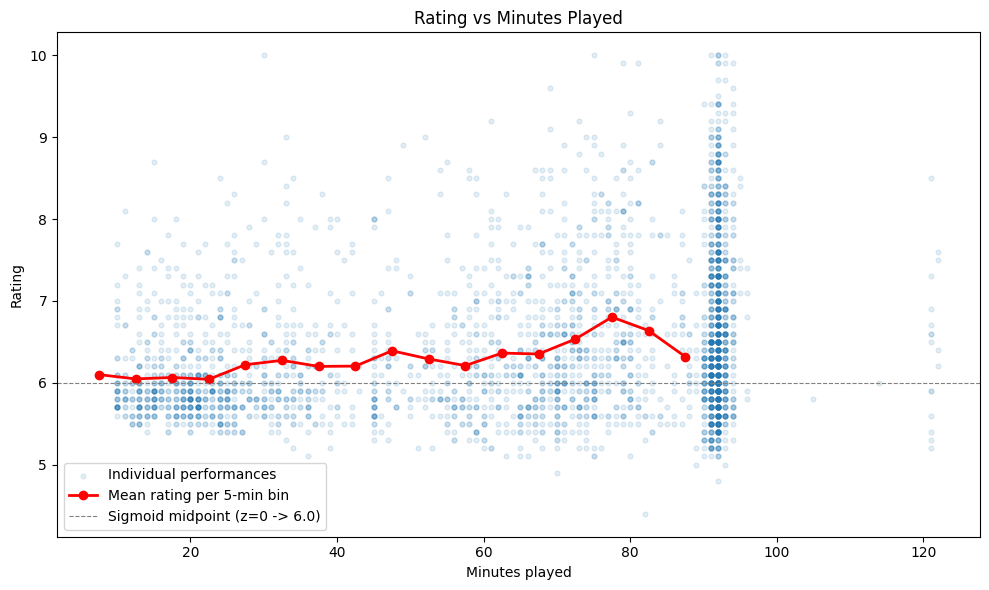

minutes_played,<=25,26-60,61-85,86-90
group,,,,
ST,6.007,6.205,6.720,6.708
Winger,5.885,6.036,6.409,6.231
WM,5.955,6.129,6.283,6.400
CM,6.086,6.145,6.660,6.216
CDM,6.140,6.394,6.514,6.820
CB,6.239,6.447,6.592,6.361
Fullback,6.049,6.404,6.388,6.068


minutes_played,<=25,26-60,61-85,86-90
group,,,,
ST,71.000,62.000,92.000,13.000
Winger,109.000,107.000,150.000,13.000
WM,11.000,17.000,18.000,1.000
CM,107.000,117.000,149.000,25.000
CDM,60.000,62.000,66.000,5.000
CB,90.000,78.000,96.000,33.000
Fullback,93.000,76.000,115.000,25.000


In [5]:
bins = np.arange(0, 95, 5)
perf["minute_bin"] = pd.cut(perf["minutes_played"], bins)
binned = perf.groupby("minute_bin", observed=True)["rating"].agg(["mean", "count"])
binned = binned[binned["count"] >= MIN_BIN_ROWS]
fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(perf["minutes_played"], perf["rating"], alpha=0.12, s=12, label="Individual performances")
ax.plot([iv.mid for iv in binned.index], binned["mean"], color="red", linewidth=2, marker="o", label="Mean rating per 5-min bin")
ax.axhline(6.0, color="gray", linestyle="--", linewidth=0.8, label="Sigmoid midpoint (z=0 -> 6.0)")
ax.set_xlabel("Minutes played"); ax.set_ylabel("Rating"); ax.set_title("Rating vs Minutes Played")
ax.legend(); plt.tight_layout(); plt.show()

single = perf[perf["n_positions"] == 1]
band = pd.cut(single["minutes_played"], [0, 25, 60, 85, 90], labels=["<=25", "26-60", "61-85", "86-90"])
means = single.pivot_table(index="group", columns=band, values="rating", aggfunc="mean", observed=True)
counts_ = single.pivot_table(index="group", columns=band, values="rating", aggfunc="count", observed=True)
order = [g for g in GROUP_ORDER if g in usable]
display(means.reindex(order))
counts_.reindex(order)

In [6]:
first = binned["mean"].iloc[:4].mean()
peak_bin, peak = binned["mean"].idxmax(), binned["mean"].max()
last_bin = binned.index[-1]
rise = (means.reindex(order)["86-90"] - means.reindex(order)["<=25"]).dropna().sort_values(ascending=False)
thin = counts_.reindex(order)["86-90"][lambda s: s < MIN_BIN_ROWS].index.tolist()
say(
    f"**Minutes.** Ratings average {first:.2f} over the first four 5-minute bins, peak at **{peak:.2f}** in {peak_bin} and are "
    f"{binned['mean'].iloc[-1]:.2f} in {last_bin} ({int(binned['count'].iloc[-1])} rows). Comparing the last minute band with the first by position, "
    f"the biggest rise is {rise.index[0]} ({rise.iloc[0]:+.2f}) and the biggest fall {rise.index[-1]} ({rise.iloc[-1]:+.2f})"
    + (f"; the 86-90 band is thin (under {MIN_BIN_ROWS} rows) for {', '.join(thin)}." if thin else ".")
)

**Minutes.** Ratings average 6.06 over the first four 5-minute bins, peak at **6.80** in (75, 80] and are 6.32 in (85, 90] (120 rows). Comparing the last minute band with the first by position, the biggest rise is ST (+0.70) and the biggest fall Fullback (+0.02); the 86-90 band is thin (under 10 rows) for WM, CDM.

### A2. Rating vs match supremacy scalar

The scalar is a match-level quantity applied to every player (positive = dominant-team deduction, negative = siege bonus). Because the
decomposition splits the rating into `pre_supremacy = base_rating + bonus` and the deduction itself, "what the players did" and "what the
scalar did" can be separated.

,n,rating,pre_supremacy,deduction
scalar_bin,,,,
"(-0.211, -0.165]",51,6.353,6.195,-0.155
"(-0.165, -0.119]",40,6.393,6.289,-0.107
"(-0.119, -0.0726]",34,6.453,6.371,-0.074
"(-0.0726, -0.0265]",78,6.150,6.109,-0.040
"(-0.0265, 0.0196]",165,6.178,6.183,0.002
"(0.0196, 0.0657]",224,6.232,6.266,0.033
"(0.0657, 0.112]",392,6.299,6.371,0.073
"(0.112, 0.158]",476,6.306,6.414,0.108
"(0.158, 0.204]",329,6.404,6.552,0.146


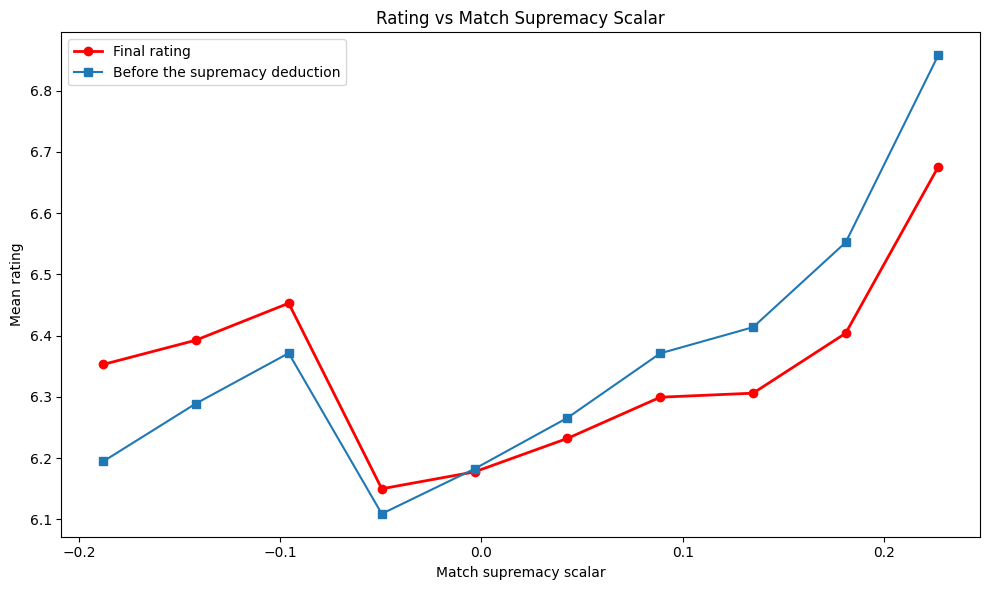

,share with siege bonus (scalar < 0)
career,
arsenal_2,0.068
ipswich_3,0.457
valencia_cf_1,0.050


In [7]:
dec["scalar_bin"] = pd.cut(dec["supremacy_scalar"], bins=10)
by_scalar = dec.groupby("scalar_bin", observed=True).agg(
    n=("rating", "size"), rating=("rating", "mean"), pre_supremacy=("pre_supremacy", "mean"), deduction=("supremacy_deduction", "mean"),
)
by_scalar = by_scalar[by_scalar["n"] >= MIN_BIN_ROWS]
display(by_scalar)
fig, ax = plt.subplots(figsize=(10, 6))
x = [iv.mid for iv in by_scalar.index]
ax.plot(x, by_scalar["rating"], marker="o", color="red", linewidth=2, label="Final rating")
ax.plot(x, by_scalar["pre_supremacy"], marker="s", color="tab:blue", label="Before the supremacy deduction")
ax.set_xlabel("Match supremacy scalar"); ax.set_ylabel("Mean rating"); ax.set_title("Rating vs Match Supremacy Scalar")
ax.legend(); plt.tight_layout(); plt.show()
siege = dec.groupby("career")["supremacy_scalar"].apply(lambda s: (s < 0).mean())
pd.DataFrame({"share with siege bonus (scalar < 0)": siege})

In [8]:
lo_bin, hi_bin = by_scalar.index[0], by_scalar.index[-1]
say(
    f"**Supremacy scalar.** It ranges {dec['supremacy_scalar'].min():.3f} to {dec['supremacy_scalar'].max():.3f}. In the lowest-scalar bin "
    f"(heaviest siege) performances rate {by_scalar.loc[lo_bin, 'pre_supremacy']:.2f} before the deduction and {by_scalar.loc[lo_bin, 'rating']:.2f} after "
    f"(the scalar adds {-by_scalar.loc[lo_bin, 'deduction']:+.2f}); in the highest bin they rate {by_scalar.loc[hi_bin, 'pre_supremacy']:.2f} before and "
    f"{by_scalar.loc[hi_bin, 'rating']:.2f} after (it takes off {by_scalar.loc[hi_bin, 'deduction']:.2f}). "
    + ("So performances in siege matches are weaker before any deduction, and the scalar partly compensates." if by_scalar.loc[lo_bin, 'pre_supremacy'] < by_scalar.loc[hi_bin, 'pre_supremacy']
       else "So performances in siege matches are not weaker before the deduction.")
    + f" The siege-bonus branch applies to {(dec['supremacy_scalar'] < 0).mean():.1%} of performances overall ("
    + ", ".join(f"{c} {v:.1%}" for c, v in siege.items()) + ")."
)

**Supremacy scalar.** It ranges -0.211 to 0.250. In the lowest-scalar bin (heaviest siege) performances rate 6.19 before the deduction and 6.35 after (the scalar adds +0.15); in the highest bin they rate 6.86 before and 6.68 after (it takes off 0.18). So performances in siege matches are weaker before any deduction, and the scalar partly compensates. The siege-bonus branch applies to 9.2% of performances overall (arsenal_2 6.8%, ipswich_3 45.7%, valencia_cf_1 5.0%).

### A3. Output histogram

,n,mean,median,sd,skew,share 5.5-6.5,share >=8,share >=9,share >=9.5,share ==10
arsenal_2,532.000,6.705,6.400,0.931,0.877,0.538,0.135,0.021,0.006,0.002
ipswich_3,291.000,6.339,6.200,0.758,1.563,0.680,0.041,0.014,0.007,0.000
valencia_cf_1,"2,219.000",6.411,6.100,0.922,1.273,0.601,0.085,0.018,0.006,0.003
All,"3,042.000",6.455,6.200,0.916,1.208,0.598,0.089,0.018,0.006,0.002


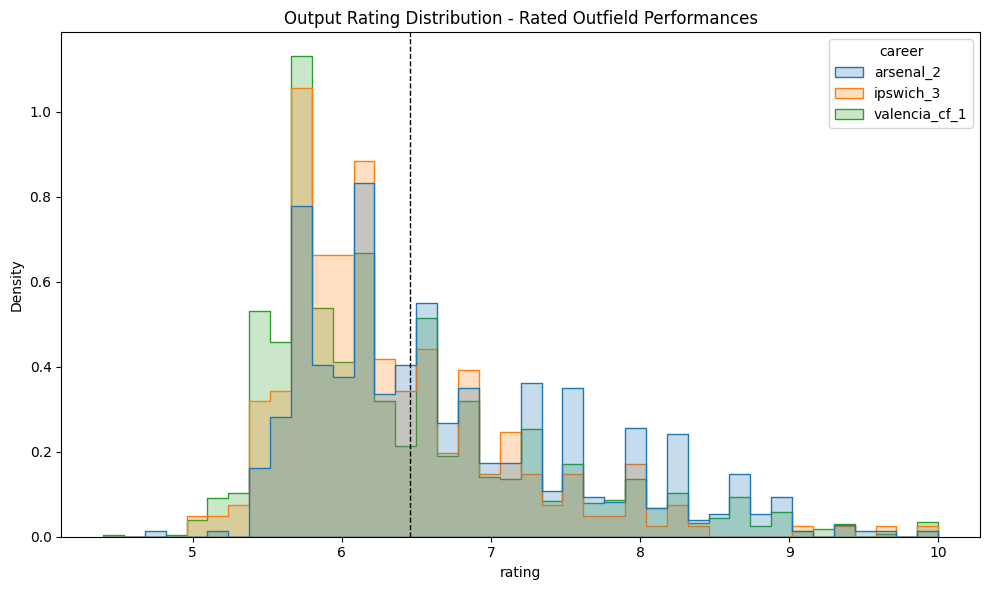

In [9]:
def dist_summary(r: pd.Series) -> pd.Series:
    return pd.Series({
        "n": len(r), "mean": r.mean(), "median": r.median(), "sd": r.std(), "skew": r.skew(),
        "share 5.5-6.5": r.between(5.5, 6.5).mean(), "share >=8": (r >= 8).mean(),
        "share >=9": (r >= 9).mean(), "share >=9.5": (r >= 9.5).mean(), "share ==10": (r == 10).mean(),
    })


summary = pd.concat([perf.groupby("career")["rating"].apply(dist_summary).unstack(), dist_summary(perf["rating"]).to_frame("All").T])
display(summary)
fig, ax = plt.subplots(figsize=(10, 6))
sns.histplot(data=perf, x="rating", hue="career", bins=40, stat="density", common_norm=False, element="step", ax=ax)
ax.axvline(perf["rating"].mean(), color="black", linestyle="--", linewidth=1)
ax.set_title("Output Rating Distribution - Rated Outfield Performances"); plt.tight_layout(); plt.show()

In [10]:
a = summary.loc["All"]
say(
    f"**Distribution (outfield).** Mean {a['mean']:.2f}, median {a['median']:.2f}, sd {a['sd']:.2f}, skew {a['skew']:.2f}; "
    f"{a['share 5.5-6.5']:.0%} of ratings lie in 5.5-6.5, {a['share >=8']:.1%} reach 8 or more, {a['share >=9']:.1%} reach 9 or more and "
    f"{a['share ==10']:.2%} are exactly 10. By career the mean is "
    + ", ".join(f"{c} {summary.loc[c, 'mean']:.2f}" for c in perf['career'].unique()) + "."
)

**Distribution (outfield).** Mean 6.46, median 6.20, sd 0.92, skew 1.21; 60% of ratings lie in 5.5-6.5, 8.9% reach 8 or more, 1.8% reach 9 or more and 0.23% are exactly 10. By career the mean is arsenal_2 6.70, ipswich_3 6.34, valencia_cf_1 6.41.

### A4. Goalkeepers and the derived positions

Goalkeepers use their own pipeline (a heuristic on xG prevented and saves, with hand-set floors and bonuses). The wide midfielders, CAM
and wing-backs are derived from proxy positions until they have data of their own (see `00_fit_stability`).

In [11]:
gk_summary = gk.groupby("career")["rating"].agg(rows="size", mean="mean", sd="std", min="min", max="max")
gk_summary.loc["All"] = [len(gk), gk["rating"].mean(), gk["rating"].std(), gk["rating"].min(), gk["rating"].max()]
display(gk_summary)
by_pos = perf.groupby("primary_position")["rating"].agg(rows="size", mean="mean", sd="std", share_ge_8=lambda x: (x >= 8).mean())
by_pos.sort_values("mean", ascending=False)

,rows,mean,sd,min,max
career,,,,,
arsenal_2,38.000,6.037,1.397,4.400,8.700
ipswich_3,22.000,7.205,1.765,4.500,10.000
valencia_cf_1,157.000,6.585,1.262,4.400,9.900
All,217.000,6.552,1.371,4.400,10.000


,rows,mean,sd,share_ge_8
primary_position,,,,
CDM,330,6.549,0.853,0.100
RB,289,6.546,0.814,0.069
CB,579,6.539,0.876,0.085
ST,333,6.538,1.101,0.141
CAM,29,6.479,0.858,0.034
RW,275,6.458,1.073,0.127
CM,570,6.418,0.905,0.081
LW,286,6.301,0.881,0.066
LM,37,6.297,0.644,0.000


In [12]:
derived_positions = [p for p in ("LM", "RM", "CAM", "LWB", "RWB") if p in by_pos.index]
other = perf[~perf["primary_position"].isin(["LM", "RM", "CAM", "LWB", "RWB"])]["rating"]
say(
    f"**Goalkeepers.** {len(gk)} rated, mean {gk['rating'].mean():.2f} (sd {gk['rating'].std():.2f}), from {gk['rating'].min():.1f} to {gk['rating'].max():.1f}; "
    f"{(gk['rating'] >= 8).mean():.1%} reach 8 or more and {(gk['rating'] <= 4.5).mean():.1%} are 4.5 or lower. "
    f"**Derived positions** ({', '.join(derived_positions) if derived_positions else 'none with data'}): mean rating "
    f"{perf[perf['primary_position'].isin(derived_positions)]['rating'].mean():.2f} against {other.mean():.2f} for fitted positions."
)

**Goalkeepers.** 217 rated, mean 6.55 (sd 1.37), from 4.4 to 10.0; 19.4% reach 8 or more and 6.9% are 4.5 or lower. **Derived positions** (LM, RM, CAM): mean rating 6.30 against 6.46 for fitted positions.

# B. Cross-position scale

Comparing achieved ratings directly is circular (if strikers genuinely perform better they should rate higher), so performances are matched on
*within-position percentile of the dot product*, the pre-sigmoid quality score. At a matched percentile every position is equally elite relative
to its peers, so a remaining rating gap comes from the post-sigmoid terms.

### B1. Rating vs within-position percentile

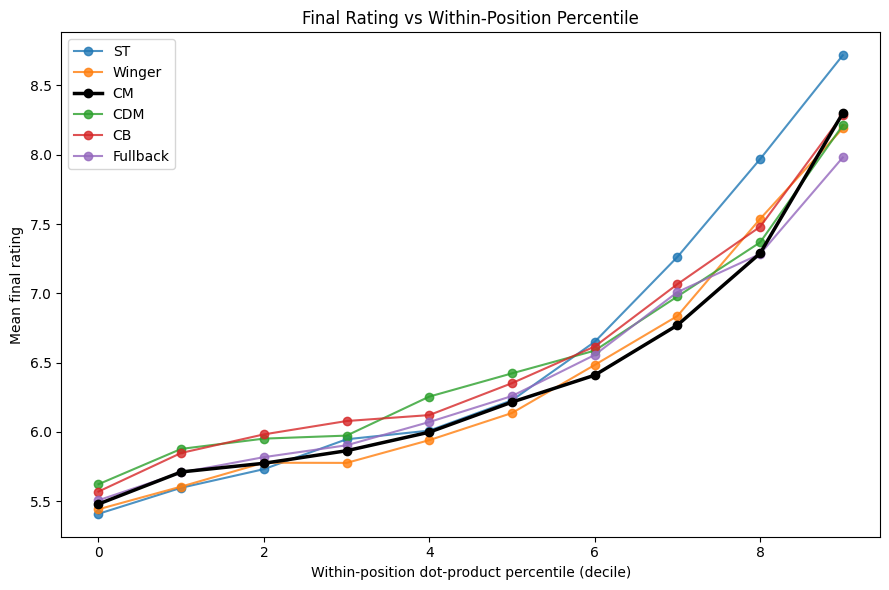

group,CB,CDM,CM,Fullback,ST,Winger
dot_bin,,,,,,
0,5.570,5.623,5.480,5.507,5.409,5.442
1,5.848,5.877,5.711,5.707,5.597,5.605
2,5.982,5.952,5.774,5.818,5.731,5.778
3,6.079,5.973,5.864,5.904,5.947,5.776
4,6.121,6.255,5.998,6.071,6.009,5.941
5,6.352,6.423,6.215,6.259,6.228,6.136
6,6.616,6.587,6.409,6.555,6.650,6.483
7,7.066,6.977,6.770,7.009,7.263,6.836
8,7.480,7.368,7.289,7.284,7.969,7.537


In [13]:
dec_g["dot_pct"] = dec_g.groupby("group")["dot"].rank(pct=True) * 100
dec_g["dot_bin"] = dec_g.groupby("group")["dot_pct"].transform(lambda x: pd.cut(x, bins=N_PERCENTILE_BINS, labels=False, include_lowest=True))
binned_dot = dec_g.groupby(["group", "dot_bin"]).agg(mean_rating=("rating", "mean"), n=("rating", "size")).reset_index()
thin = binned_dot["n"] < MIN_SAMPLES_PER_BIN
plot_bins = binned_dot[~thin]
plt.figure(figsize=(9, 6))
for group in usable:
    sub = plot_bins[plot_bins["group"] == group].sort_values("dot_bin")
    if sub.empty:
        continue
    style = {"color": "black", "linewidth": 2.5, "zorder": 10} if group == REFERENCE_POSITION else {"linewidth": 1.5, "alpha": 0.8}
    plt.plot(sub["dot_bin"], sub["mean_rating"], marker="o", label=group, **style)
plt.xlabel("Within-position dot-product percentile (decile)"); plt.ylabel("Mean final rating")
plt.title("Final Rating vs Within-Position Percentile"); plt.legend(); plt.tight_layout(); plt.show()
curve = plot_bins.pivot(index="dot_bin", columns="group", values="mean_rating")
curve

In [14]:
top_decile_rating = curve.iloc[-1].sort_values(ascending=False)
no_curve = [g for g in usable if g not in curve.columns]
say(
    f"**Matched-percentile curves.** In the top decile the mean rating is "
    + ", ".join(f"{g} {v:.2f}" for g, v in top_decile_rating.items())
    + f"; the lowest decile ranges {curve.iloc[0].min():.2f} to {curve.iloc[0].max():.2f}."
    + (f" Not plotted (every decile thinner than {MIN_SAMPLES_PER_BIN} rows): {', '.join(no_curve)}." if no_curve else "")
)

**Matched-percentile curves.** In the top decile the mean rating is ST 8.72, CM 8.30, CB 8.29, CDM 8.21, Winger 8.19, Fullback 7.98; the lowest decile ranges 5.41 to 5.62. Not plotted (every decile thinner than 15 rows): WM.

### B2. Where the top-decile gap comes from

Top decile (90th percentile and above of the dot product, within each position). Bars add up to the pre-clamp rating:
`base_rating + event_bonus (goals, assists) + other_bonus (mastery, position modifiers) - supremacy_deduction`.

,rating,base_rating,event_bonus,other_bonus,supremacy_deduction,n
group,,,,,,
ST,8.718,7.599,1.007,0.206,0.080,33
Winger,8.191,7.450,0.792,0.032,0.089,55
WM,7.300,7.023,0.350,0.022,0.091,7
CM,8.300,7.422,0.458,0.526,0.101,54
CDM,8.213,7.385,0.094,0.823,0.087,31
CB,8.289,7.502,0.025,0.806,0.037,57
Fullback,7.981,7.318,0.080,0.662,0.080,57


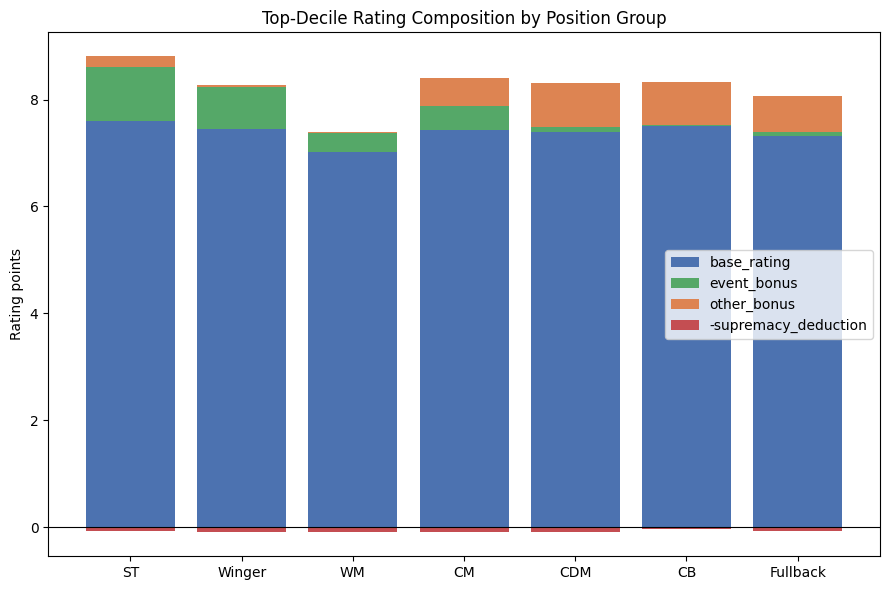

metric,rating,base_rating,event_bonus,other_bonus
group,,,,
CB,-0.011,0.080,-0.434,0.280
CDM,-0.087,-0.037,-0.365,0.297
Fullback,-0.319,-0.104,-0.378,0.136
ST,0.418,0.177,0.549,-0.319
Winger,-0.109,0.029,0.334,-0.493


In [15]:
PARTS = ["rating", "base_rating", "event_bonus", "other_bonus", "supremacy_deduction"]


def top_decile(df: pd.DataFrame, score: str, floor: float = 90.0) -> pd.DataFrame:
    pct = df.groupby("group")[score].rank(pct=True) * 100
    return df[pct >= floor]


def composition(top: pd.DataFrame) -> pd.DataFrame:
    comp = top.groupby("group")[PARTS].mean().reindex([g for g in GROUP_ORDER if g in usable])
    comp["n"] = top.groupby("group").size().reindex(comp.index)
    return comp


def composition_plot(comp: pd.DataFrame, title: str) -> None:
    plt.figure(figsize=(9, 6))
    bottom = np.zeros(len(comp))
    for part, colour in [("base_rating", "#4c72b0"), ("event_bonus", "#55a868"), ("other_bonus", "#dd8452")]:
        plt.bar(comp.index, comp[part].clip(lower=0), bottom=bottom, label=part, color=colour)
        bottom += comp[part].clip(lower=0).values
    plt.bar(comp.index, -comp["supremacy_deduction"], label="-supremacy_deduction", color="#c44e52")
    plt.axhline(0, color="black", linewidth=0.8)
    plt.ylabel("Rating points"); plt.title(title); plt.legend(); plt.tight_layout(); plt.show()


def gap_table(top: pd.DataFrame, metrics=("rating", "base_rating", "event_bonus", "other_bonus")) -> pd.DataFrame:
    ref = top[top["group"] == REFERENCE_POSITION]
    rows = []
    for group in [g for g in GROUP_ORDER if g in usable and g != REFERENCE_POSITION]:
        sub = top[top["group"] == group]
        if len(sub) < MIN_TOP_ROWS:
            continue
        for metric in metrics:
            est = inference.mean_gap_bootstrap(sub[metric], ref[metric], N_BOOTSTRAP_RESAMPLES, RANDOM_SEED)
            rows.append({"group": group, "metric": metric, "n": len(sub), "gap_vs_cm": est.estimate, "ci_low": est.ci_low,
                         "ci_high": est.ci_high, "excludes_zero": bool(est.ci_low > 0 or est.ci_high < 0),
                         "band": classify_scale_gap(est.estimate) if metric == "rating" else ""})
    return pd.DataFrame(rows)


def describe_gaps(gaps: pd.DataFrame, parts=("event_bonus", "base_rating")) -> str:
    out = []
    for group, g in gaps.groupby("group", sort=False):
        r = g[g["metric"] == "rating"].iloc[0]
        text = f"{group} {r['gap_vs_cm']:+.2f} [{r['ci_low']:+.2f}, {r['ci_high']:+.2f}]"
        if r["excludes_zero"]:
            text += " (" + ", ".join(f"{p.replace('_', ' ')} {g.loc[g['metric'] == p, 'gap_vs_cm'].iloc[0]:+.2f}" for p in parts) + ")"
        out.append(text)
    return "; ".join(out)


top_dot = top_decile(dec_g, "dot")
comp_dot = composition(top_dot)
display(comp_dot)
composition_plot(comp_dot, "Top-Decile Rating Composition by Position Group")
gaps_dot = gap_table(top_dot)
gaps_dot.pivot(index="group", columns="metric", values="gap_vs_cm")[["rating", "base_rating", "event_bonus", "other_bonus"]]

In [16]:
small = [g for g in usable if g != REFERENCE_POSITION and g not in set(gaps_dot["group"])]
say(
    f"**Top-decile gap to {REFERENCE_POSITION} (rating points; intervals excluding zero show their main sources).** " + describe_gaps(gaps_dot)
    + (f". Not compared (top decile under {MIN_TOP_ROWS} rows): {', '.join(small)}." if small else ".")
)

**Top-decile gap to CM (rating points; intervals excluding zero show their main sources).** ST +0.42 [+0.12, +0.72] (event bonus +0.55, base rating +0.18); Winger -0.11 [-0.40, +0.17]; CDM -0.09 [-0.38, +0.20]; CB -0.01 [-0.26, +0.25]; Fullback -0.32 [-0.58, -0.06] (event bonus -0.38, base rating -0.10). Not compared (top decile under 10 rows): WM.

### B3. Re-ranking on non-scoring quality only

`dot` already contains each position's own weighting of goals and assists, so "top decile by dot" partly self-selects for scoring performances among
attacking positions before any bonus. Re-ranking on `non_scoring_dot` (dot minus the goals/assists contribution) removes that self-selection.

,rating,base_rating,event_bonus,other_bonus,supremacy_deduction,n
group,,,,,,
ST,8.173,7.384,0.688,0.195,0.091,33
Winger,7.876,7.403,0.532,0.028,0.089,55
WM,6.857,6.927,0.043,-0.027,0.087,7
CM,8.074,7.375,0.258,0.541,0.094,54
CDM,8.226,7.383,0.078,0.849,0.084,31
CB,8.239,7.478,0.007,0.795,0.035,57
Fullback,7.944,7.305,0.049,0.666,0.079,57


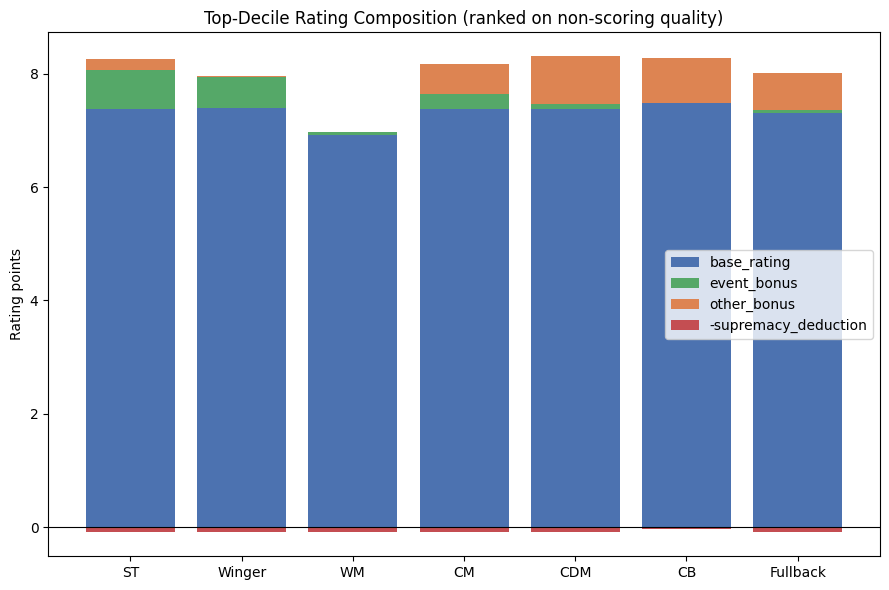

metric,rating,base_rating,event_bonus,other_bonus
group,,,,
CB,0.165,0.103,-0.251,0.254
CDM,0.152,0.008,-0.181,0.309
Fullback,-0.130,-0.070,-0.209,0.125
ST,0.099,0.008,0.429,-0.346
Winger,-0.198,0.028,0.273,-0.513


,group,n,gap_vs_cm,ci_low,ci_high,excludes_zero,band
0,ST,33,0.099,-0.270,0.489,False,comparable
4,Winger,55,-0.198,-0.524,0.127,False,comparable
8,CDM,31,0.152,-0.161,0.471,False,comparable
12,CB,57,0.165,-0.128,0.457,False,comparable
16,Fullback,57,-0.130,-0.424,0.164,False,comparable


In [17]:
top_clean = top_decile(dec_g, "non_scoring_dot")
comp_clean = composition(top_clean)
display(comp_clean)
composition_plot(comp_clean, "Top-Decile Rating Composition (ranked on non-scoring quality)")
gaps_clean = gap_table(top_clean)
display(gaps_clean.pivot(index="group", columns="metric", values="gap_vs_cm")[["rating", "base_rating", "event_bonus", "other_bonus"]])
gaps_clean[gaps_clean["metric"] == "rating"].drop(columns="metric")

In [18]:
sig = gaps_clean[(gaps_clean["metric"] == "rating") & gaps_clean["excludes_zero"]]
say(
    f"**After removing scoring from the ranking.** " + describe_gaps(gaps_clean) + ". "
    + (f"Gaps whose interval excludes zero: {', '.join(sig['group'])}." if len(sig) else "No gap to CM has an interval that excludes zero.")
)

**After removing scoring from the ranking.** ST +0.10 [-0.27, +0.49]; Winger -0.20 [-0.52, +0.13]; CDM +0.15 [-0.16, +0.47]; CB +0.16 [-0.13, +0.46]; Fullback -0.13 [-0.42, +0.16]. No gap to CM has an interval that excludes zero.

### B4. Does the asymmetry hold in every career?

Rating gap to CM at the top non-scoring **quintile** (a top decile leaves too few rows per career), by career. Groups need `MIN_GROUP_ROWS` rows in
the career and `MIN_TOP_ROWS` in the top quintile.

In [19]:
rows = []
for career, sub in dec_g.groupby("career"):
    top = top_decile(sub, "non_scoring_dot", floor=80.0)
    ref = top[top["group"] == REFERENCE_POSITION]
    sizes = sub["group"].value_counts()
    for group in [g for g in GROUP_ORDER if g in usable and g != REFERENCE_POSITION]:
        grp = top[top["group"] == group]
        if sizes.get(group, 0) < MIN_GROUP_ROWS or len(grp) < MIN_TOP_ROWS or len(ref) < MIN_TOP_ROWS:
            continue
        est = inference.mean_gap_bootstrap(grp["rating"], ref["rating"], N_BOOTSTRAP_RESAMPLES, RANDOM_SEED)
        rows.append({"career": career, "group": group, "n_top": len(grp), "n_cm_top": len(ref),
                     "rating_gap_vs_cm": est.estimate, "ci_low": est.ci_low, "ci_high": est.ci_high})
by_career = pd.DataFrame(rows)
display(by_career.pivot(index="group", columns="career", values="rating_gap_vs_cm"))
by_career.round(3)

career,arsenal_2,valencia_cf_1
group,,
CB,-0.017,0.268
CDM,-0.123,0.218
Fullback,0.300,-0.156
ST,0.688,0.156
Winger,0.384,-0.439


,career,group,n_top,n_cm_top,rating_gap_vs_cm,ci_low,ci_high
0,arsenal_2,ST,12,21,0.688,0.138,1.225
1,arsenal_2,Winger,19,21,0.384,-0.063,0.832
2,arsenal_2,CDM,11,21,-0.123,-0.570,0.313
3,arsenal_2,CB,18,21,-0.017,-0.367,0.333
4,arsenal_2,Fullback,22,21,0.300,-0.044,0.656
5,valencia_cf_1,ST,48,86,0.156,-0.163,0.470
6,valencia_cf_1,Winger,91,86,-0.439,-0.724,-0.159
7,valencia_cf_1,CDM,40,86,0.218,-0.089,0.515
8,valencia_cf_1,CB,85,86,0.268,0.018,0.514
9,valencia_cf_1,Fullback,81,86,-0.156,-0.389,0.089


In [20]:
if len(by_career):
    spread = by_career.groupby("group")["rating_gap_vs_cm"].agg(["min", "max", "count"])
    multi = spread[spread["count"] > 1]
    say(
        "**By career (top non-scoring quintile, gap to CM).** "
        + "; ".join(f"{g} {r['min']:+.2f} to {r['max']:+.2f} across {int(r['count'])} careers" for g, r in multi.iterrows())
        + ". " + ("Groups appear in only one career: " + ", ".join(spread.index[spread["count"] == 1]) + "." if (spread["count"] == 1).any() else "")
    )
else:
    say("No group had enough rows in a single career for this comparison.")

**By career (top non-scoring quintile, gap to CM).** CB -0.02 to +0.27 across 2 careers; CDM -0.12 to +0.22 across 2 careers; Fullback -0.16 to +0.30 across 2 careers; ST +0.16 to +0.69 across 2 careers; Winger -0.44 to +0.38 across 2 careers. 

### B5. High-rating shares and team context

Descriptive shares cannot separate the bonus mechanism from real spread differences (hence B1-B3) but show the absolute asymmetry. The team-context
check asks whether non-scoring quality is coupled to how dominant the team was (Spearman against xG differential, cluster bootstrap by match).

In [21]:
shares = (dec_g.groupby("group")["rating"]
          .agg(n="size", share_ge_8=lambda x: (x >= 8).mean(), share_ge_9=lambda x: (x >= 9).mean())
          .reindex([g for g in GROUP_ORDER if g in usable]))
display(shares)
rows = []
for group in [g for g in GROUP_ORDER if g in usable]:
    sub = dec_g[dec_g["group"] == group].dropna(subset=["xg_diff"])
    est = inference.cluster_bootstrap_spearman(sub["non_scoring_dot"], sub["xg_diff"], sub["match_key"], N_BOOTSTRAP_RESAMPLES, RANDOM_SEED)
    rows.append({"group": group, "n": len(sub), "rho": est.estimate, "ci_low": est.ci_low, "ci_high": est.ci_high})
context_rho = pd.DataFrame(rows).set_index("group")
context_rho

,n,share_ge_8,share_ge_9
group,,,
ST,322,0.146,0.037
Winger,546,0.097,0.022
WM,69,0.014,0.000
CM,536,0.073,0.019
CDM,308,0.091,0.013
CB,560,0.086,0.014
Fullback,562,0.071,0.005


,n,rho,ci_low,ci_high
group,,,,
ST,322,0.214,0.105,0.318
Winger,546,0.356,0.266,0.441
WM,69,0.315,0.070,0.493
CM,536,0.279,0.192,0.361
CDM,308,0.148,0.042,0.256
CB,560,0.088,-0.007,0.181
Fullback,562,0.079,-0.007,0.162


In [22]:
flat = context_rho.index[(context_rho["ci_low"] <= 0) & (context_rho["ci_high"] >= 0)].tolist()
say(
    f"**High ratings.** Share rated 8 or more: " + ", ".join(f"{g} {r['share_ge_8']:.1%}" for g, r in shares.iterrows())
    + "; 9 or more: " + ", ".join(f"{g} {r['share_ge_9']:.1%}" for g, r in shares.iterrows())
    + f". **Team context.** Non-scoring quality correlates with xG differential at "
    + ", ".join(f"{g} {r['rho']:.2f}" for g, r in context_rho.iterrows())
    + (f"; the interval includes zero for {', '.join(flat)}." if flat else "; every interval excludes zero.")
)

**High ratings.** Share rated 8 or more: ST 14.6%, Winger 9.7%, WM 1.4%, CM 7.3%, CDM 9.1%, CB 8.6%, Fullback 7.1%; 9 or more: ST 3.7%, Winger 2.2%, WM 0.0%, CM 1.9%, CDM 1.3%, CB 1.4%, Fullback 0.5%. **Team context.** Non-scoring quality correlates with xG differential at ST 0.21, Winger 0.36, WM 0.31, CM 0.28, CDM 0.15, CB 0.09, Fullback 0.08; the interval includes zero for CB, Fullback.

# C. Ceilings

Bonuses are post-sigmoid and capped by explicit constants, so ceilings are read from what is observable: empirical maxima, how often the 0-10
clamp bites, and how many events each position needs to reach the bonus caps (from the service's own functions and constants).

### C1. Empirical ceiling

In [23]:
ceiling = (dec_g.groupby("group")["rating"]
           .agg(n="size", max="max", p99=lambda x: x.quantile(0.99), p95=lambda x: x.quantile(0.95),
                share_ge_9=lambda x: (x >= 9).mean(), share_ge_9_5=lambda x: (x >= 9.5).mean())
           .reindex([g for g in GROUP_ORDER if g in usable]))
ceiling["share_clamped_at_10"] = dec_g.groupby("group")["unclipped"].apply(lambda x: (x > 10).mean())
ceiling

,n,max,p99,p95,share_ge_9,share_ge_9_5,share_clamped_at_10
group,,,,,,,
ST,322,10.000,9.837,8.795,0.037,0.016,0.006
Winger,546,10.000,9.400,8.400,0.022,0.009,0.004
WM,69,8.800,7.984,7.220,0.000,0.000,0.000
CM,536,10.000,9.200,8.325,0.019,0.007,0.002
CDM,308,9.400,9.079,8.300,0.013,0.000,0.000
CB,560,10.000,9.000,8.305,0.014,0.002,0.002
Fullback,562,9.500,8.800,8.195,0.005,0.002,0.000


### C2. Bonus caps and how many events reach them

In [24]:
svc = rating.load_service()
POSITION_FOR_GROUP = {"ST": "ST", "Winger": "RW", "WM": "RM", "CAM": "CAM", "CM": "CM", "CDM": "CDM", "CB": "CB", "Fullback": "RB"}


def events_to_cap(fn, cap: float, pos: str) -> float:
    return next((n for n in range(1, 13) if fn(n, pos) >= cap - 1e-9), np.nan)


rows = []
for group in [g for g in GROUP_ORDER if g in usable]:
    pos = POSITION_FOR_GROUP[group]
    sub = dec_g[dec_g["group"] == group]
    rows.append({
        "group": group,
        "goal_bonus_1": svc._calculate_goal_bonus(1, pos), "goal_bonus_2": svc._calculate_goal_bonus(2, pos),
        "goals_to_cap": events_to_cap(svc._calculate_goal_bonus, svc.GOAL_BONUS_CAP, pos),
        "assist_bonus_1": svc._calculate_assist_bonus(1, pos),
        "assists_to_cap": events_to_cap(svc._calculate_assist_bonus, svc.ASSIST_BONUS_CAP, pos),
        "realised_max_event_bonus": sub["event_bonus"].max(), "realised_p99_event_bonus": sub["event_bonus"].quantile(0.99),
        "share_with_event_bonus": (sub["event_bonus"] > 0).mean(),
    })
caps = pd.DataFrame(rows).set_index("group")
print(f"GOAL_BONUS_CAP = {svc.GOAL_BONUS_CAP}, ASSIST_BONUS_CAP = {svc.ASSIST_BONUS_CAP}")
caps

GOAL_BONUS_CAP = 1.8, ASSIST_BONUS_CAP = 2.0


,goal_bonus_1,goal_bonus_2,goals_to_cap,assist_bonus_1,assists_to_cap,realised_max_event_bonus,realised_p99_event_bonus,share_with_event_bonus
group,,,,,,,,
ST,0.300,0.849,4,0.250,4,2.266,2.050,0.506
Winger,0.450,1.273,3,0.350,4,3.091,2.082,0.436
WM,0.350,0.990,3,0.300,4,1.800,1.153,0.290
CM,0.250,0.707,4,0.250,4,1.800,1.374,0.358
CDM,0.200,0.566,5,0.250,4,0.707,0.707,0.114
CB,0.200,0.566,5,0.200,5,0.400,0.200,0.037
Fullback,0.200,0.566,5,0.200,5,1.039,0.278,0.116


In [25]:
reaches_9 = ceiling.index[ceiling["share_ge_9"] > 0.01].tolist()
never_9 = ceiling.index[ceiling["share_ge_9"] == 0].tolist()
clamped = ceiling.index[ceiling["share_clamped_at_10"] > 0].tolist()
say(
    f"**Ceilings.** Highest rating by group: " + ", ".join(f"{g} {r['max']:.1f}" for g, r in ceiling.iterrows())
    + f". Groups where more than 1% of performances reach 9: {', '.join(reaches_9) if reaches_9 else 'none'}; groups with none at 9: "
    f"{', '.join(never_9) if never_9 else 'none'}. The 0-10 clamp bites for: {', '.join(clamped) if clamped else 'no group'}. "
    f"Goals needed to reach the goal-bonus cap ({svc.GOAL_BONUS_CAP}): " + ", ".join(f"{g} {int(r['goals_to_cap'])}" for g, r in caps.iterrows() if pd.notna(r['goals_to_cap']))
    + f"; assists for the assist cap ({svc.ASSIST_BONUS_CAP}): " + ", ".join(f"{g} {int(r['assists_to_cap'])}" for g, r in caps.iterrows() if pd.notna(r['assists_to_cap'])) + "."
)

**Ceilings.** Highest rating by group: ST 10.0, Winger 10.0, WM 8.8, CM 10.0, CDM 9.4, CB 10.0, Fullback 9.5. Groups where more than 1% of performances reach 9: ST, Winger, CM, CDM, CB; groups with none at 9: WM. The 0-10 clamp bites for: ST, Winger, CM, CB. Goals needed to reach the goal-bonus cap (1.8): ST 4, Winger 3, WM 3, CM 4, CDM 5, CB 5, Fullback 5; assists for the assist cap (2.0): ST 4, Winger 4, WM 4, CM 4, CDM 4, CB 5, Fullback 5.

## Notes and limitations

- Parts A and B describe what the output looks like and where cross-position gaps come from, not why players behave as they do; B2-B3's matched-percentile
  design is what makes the attribution fair.
- Position composition confounds pooled means: read the position-stratified results before trusting a pooled pattern. Thin cells are masked, not smoothed.
- Multi-position players enter Part A only; B and C use single-position performances. Wing-backs have no data.
- Group gaps resample each group's top-decile rows independently (players from one match are not clustered there); B5's correlation clusters by match.
- Pooled across three saves whose distance statistics sit at different levels, so position-level gaps include any save-level scale differences.

In [26]:
say(
    f"**Summary (config `{info['hash'][:8]}`).** Outfield ratings average {a['mean']:.2f} (sd {a['sd']:.2f}); "
    f"{len(sig)} position group(s) differ from {REFERENCE_POSITION} at matched non-scoring quality; "
    f"{', '.join(reaches_9) if reaches_9 else 'no group'} routinely reach 9."
)

**Summary (config `005d563f`).** Outfield ratings average 6.46 (sd 0.92); 0 position group(s) differ from CM at matched non-scoring quality; ST, Winger, CM, CDM, CB routinely reach 9.